# ERCOT - LOAD off-peak hour identification

## 1. Imports & paths

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import os

PROJECT_ROOT = Path('../..').resolve()
LOAD_DIR     = PROJECT_ROOT / '01_data' / '2_cleaned' / 'load' / 'total_load_20201231_20260526.csv'
OUT_DIR      = PROJECT_ROOT / '01_data' / '2_cleaned' / 'peak hours'
os.makedirs(OUT_DIR, exist_ok=True)

In [2]:
df = pd.read_csv(LOAD_DIR)
df

,datetime,total_load
0,2020-12-31 01:00:00,39174.39
1,2020-12-31 02:00:00,38284.84
2,2020-12-31 03:00:00,37776.69
3,2020-12-31 04:00:00,37781.84
4,2020-12-31 05:00:00,38455.69
...,...,...
47314,2026-05-26 20:00:00,66009.13
47315,2026-05-26 21:00:00,63250.91
47316,2026-05-26 22:00:00,60728.67
47317,2026-05-26 23:00:00,56995.91


In [3]:
df_analysis = df.copy()
df_analysis['datetime'] = pd.to_datetime(df_analysis['datetime'])
df_analysis['hour'] = df_analysis['datetime'].dt.hour
df_analysis['week_day'] = df_analysis['datetime'].dt.weekday
df_analysis

,datetime,total_load,hour,week_day
0,2020-12-31 01:00:00,39174.39,1,3
1,2020-12-31 02:00:00,38284.84,2,3
2,2020-12-31 03:00:00,37776.69,3,3
3,2020-12-31 04:00:00,37781.84,4,3
4,2020-12-31 05:00:00,38455.69,5,3
...,...,...,...,...
47314,2026-05-26 20:00:00,66009.13,20,1
47315,2026-05-26 21:00:00,63250.91,21,1
47316,2026-05-26 22:00:00,60728.67,22,1
47317,2026-05-26 23:00:00,56995.91,23,1


In [4]:
hourly_load_avg = df_analysis.groupby(['hour', 'week_day']).mean()['total_load'].reset_index()
hourly_load_avg

,hour,week_day,total_load
0,0,0,48184.967908
1,0,1,48743.888901
2,0,2,48838.494362
3,0,3,48541.675907
4,0,4,48907.159893
...,...,...,...
163,23,2,51442.656726
164,23,3,51731.221388
165,23,4,51504.651844
166,23,5,50572.399007


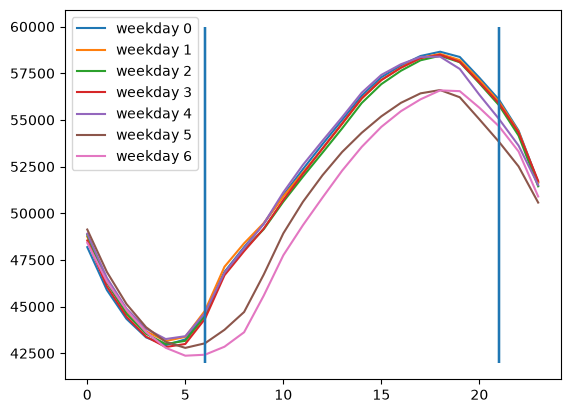

In [5]:
for week_day in range(7):
    df_wkdy = hourly_load_avg[hourly_load_avg['week_day'] == week_day]
    plt.plot(df_wkdy['hour'], df_wkdy['total_load'], label=f'weekday {week_day}')
    plt.vlines(6, 42000, 60000)
    plt.vlines(21, 42000, 60000)
plt.legend()

Notes: 
Peak hours for ERCOT
- 07:00 - 22:00 M-F (6 - 21)
- exclude NERC holidays

In [6]:
# NERC holiday dates from 2021 - 2025 (https://www.energygps.com/HomeTools/PowerCalendar)
from datetime import date

holidays = [
    date(2021, 1, 1),   # New Years
    date(2021, 5, 31),  # Memorial
    date(2021, 7, 5),   # Independence
    date(2021, 9, 6),   # Labor
    date(2021, 11, 25), # Thanksgiving
    date(2021, 12, 25), # Christmas
    date(2022, 1, 1),   # New Years
    date(2022, 5, 30),  # Memorial
    date(2022, 7, 4),   # Independence
    date(2022, 9, 5),   # Labor
    date(2022, 11, 24), # Thanksgiving
    date(2022, 12, 26), # Christmas
    date(2023, 1, 2),   # New Years
    date(2023, 5, 29),  # Memorial
    date(2023, 7, 4),   # Independence
    date(2023, 9, 4),   # Labor
    date(2023, 11, 23), # Thanksgiving
    date(2023, 12, 25), # Christmas
    date(2024, 1, 1),   # New Years
    date(2024, 5, 27),  # Memorial
    date(2024, 7, 4),   # Independence
    date(2024, 9, 2),   # Labor
    date(2024, 11, 28), # Thanksgiving
    date(2024, 12, 25), # Christmas
    date(2025, 1, 1),   # New Years
    date(2025, 5, 26),  # Memorial
    date(2025, 7, 4),   # Independence
    date(2025, 9, 1),   # Labor
    date(2025, 11, 27), # Thanksgiving
    date(2025, 12, 25), # Christmas
    date(2026, 1, 1),	# New Years
    date(2026, 5, 25)	# Memorial
]

holidays

[datetime.date(2021, 1, 1),
 datetime.date(2021, 5, 31),
 datetime.date(2021, 7, 5),
 datetime.date(2021, 9, 6),
 datetime.date(2021, 11, 25),
 datetime.date(2021, 12, 25),
 datetime.date(2022, 1, 1),
 datetime.date(2022, 5, 30),
 datetime.date(2022, 7, 4),
 datetime.date(2022, 9, 5),
 datetime.date(2022, 11, 24),
 datetime.date(2022, 12, 26),
 datetime.date(2023, 1, 2),
 datetime.date(2023, 5, 29),
 datetime.date(2023, 7, 4),
 datetime.date(2023, 9, 4),
 datetime.date(2023, 11, 23),
 datetime.date(2023, 12, 25),
 datetime.date(2024, 1, 1),
 datetime.date(2024, 5, 27),
 datetime.date(2024, 7, 4),
 datetime.date(2024, 9, 2),
 datetime.date(2024, 11, 28),
 datetime.date(2024, 12, 25),
 datetime.date(2025, 1, 1),
 datetime.date(2025, 5, 26),
 datetime.date(2025, 7, 4),
 datetime.date(2025, 9, 1),
 datetime.date(2025, 11, 27),
 datetime.date(2025, 12, 25),
 datetime.date(2026, 1, 1),
 datetime.date(2026, 5, 25)]

In [7]:
df_analysis['holidays'] = df_analysis['datetime'].dt.date.isin(holidays)
df_analysis[df_analysis['holidays'] == True]

,datetime,total_load,hour,week_day,holidays
23,2021-01-01 00:00:00,44510.41,0,4,True
24,2021-01-01 01:00:00,43713.80,1,4,True
25,2021-01-01 02:00:00,43314.37,2,4,True
26,2021-01-01 03:00:00,43048.35,3,4,True
27,2021-01-01 04:00:00,43073.65,4,4,True
...,...,...,...,...,...
47289,2026-05-25 19:00:00,67506.88,19,0,True
47290,2026-05-25 20:00:00,65222.72,20,0,True
47291,2026-05-25 21:00:00,63455.22,21,0,True
47292,2026-05-25 22:00:00,61424.35,22,0,True


### aggregate peak_hours column

In [8]:
week_day_list = list(range(5))
day_peak_hrs_list = list(range(7, 23))

df_analysis['peak_hour'] = (df_analysis['holidays'] == False) & (df_analysis['week_day'].isin(week_day_list)) & (df_analysis['hour'].isin(day_peak_hrs_list))
df_analysis.head(24)

,datetime,total_load,hour,week_day,holidays,peak_hour
0,2020-12-31 01:00:00,39174.39,1,3,False,False
1,2020-12-31 02:00:00,38284.84,2,3,False,False
2,2020-12-31 03:00:00,37776.69,3,3,False,False
3,2020-12-31 04:00:00,37781.84,4,3,False,False
4,2020-12-31 05:00:00,38455.69,5,3,False,False
5,2020-12-31 06:00:00,39872.08,6,3,False,False
6,2020-12-31 07:00:00,41885.69,7,3,False,True
7,2020-12-31 08:00:00,43811.60,8,3,False,True
8,2020-12-31 09:00:00,45548.32,9,3,False,True
9,2020-12-31 10:00:00,47221.08,10,3,False,True


In [9]:
# validate against the peak day summary

df_validation = df_analysis.groupby([df_analysis['datetime'].dt.year, df_analysis['datetime'].dt.month])['peak_hour'].sum()
df_validation

datetime  datetime
2020      12           16
2021      1           320
          2           320
          3           368
          4           352
                     ... 
2026      1           336
          2           320
          3           352
          4           352
          5           272
Name: peak_hour, Length: 66, dtype: int64

### export

In [10]:
df_export = df_analysis.filter(['datetime', 'peak_hour'])
df_export = df_export[(df_export['datetime'].dt.date >= date(2021, 1, 1)) & (df_export['datetime'].dt.date <= date(2025, 12, 31))]
df_export

,datetime,peak_hour
23,2021-01-01 00:00:00,False
24,2021-01-01 01:00:00,False
25,2021-01-01 02:00:00,False
26,2021-01-01 03:00:00,False
27,2021-01-01 04:00:00,False
...,...,...
43810,2025-12-31 19:00:00,True
43811,2025-12-31 20:00:00,True
43812,2025-12-31 21:00:00,True
43813,2025-12-31 22:00:00,True


In [11]:
df_export.to_csv(OUT_DIR / 'peak_hour_2021_2025.csv', index=False)